# 01 · Arquitectura y reactividad

[Índice del frontend](README.md) · [Anterior · Ejecución y herramientas](00_ejecucion_y_herramientas.ipynb) · [Siguiente · HTTP, sesión y tiempo real](02_http_sesion_y_tiempo_real.ipynb)

## Dónde empieza la aplicación

`index.html` declara `<div id="app">`. `src/main.js` importa `App.svelte` y la hoja global `style.css`,
y monta el componente con `mount(App, { target })`. Cada componente Svelte combina lógica JavaScript
y una plantilla declarativa. La plantilla define qué elementos existen y qué valores muestran para el
estado actual. Al compilarla, Svelte obtiene las dependencias que debe mantener actualizadas.

| Módulo | Responsabilidad |
| --- | --- |
| `App.svelte` | Consulta la sesión al montar. Decide entre carga inicial, inicio de sesión y dashboard. |
| `GUI/views/Login.svelte` | Captura usuario y contraseña. Muestra validación y reenvía el evento al componente raíz. |
| `GUI/views/Dashboard.svelte` | Mantiene dispositivo y vista activos. Abre el flujo en vivo y consulta la tendencia. |
| `GUI/views/HistoryTable.svelte` | Separa fechas en edición y aplicadas. Gestiona página, recarga y exportación. |
| `GUI/components/SeriesChart.svelte` | Transforma puntos de la API en una gráfica de Chart.js. |
| `GUI/components/Brand.svelte` | Reutiliza el nombre y símbolo del monitor en las vistas. |
| `models/api.js` | Agrupa el prefijo HTTP, los errores de estado y la construcción de consultas. |
| `models/telemetry.js` | Declara métricas, periodos, iconos, colores y formatos. |

- [main.js](../../frontend/src/main.js)
- [App.svelte](../../frontend/src/App.svelte)
- [models/telemetry.js](../../frontend/src/models/telemetry.js)

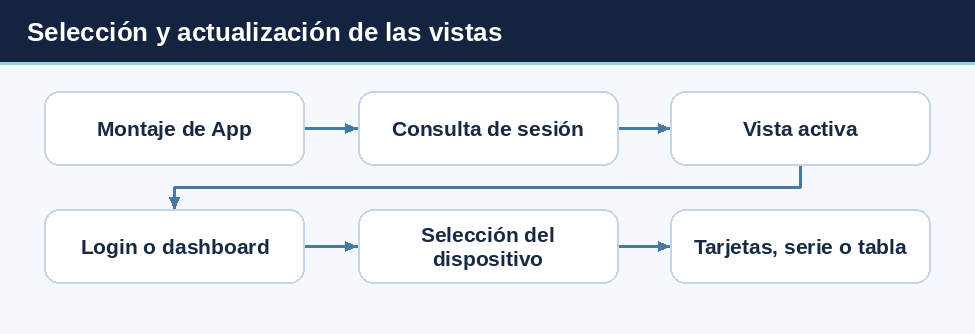

## Runas y ciclo de vida en Svelte 5

| Sintaxis | Qué expresa | Ejemplo del repositorio |
| --- | --- | --- |
| `$state(valor)` | Valor reactivo que la vista puede cambiar. | `selectedId`, `view` y `periodKey`. |
| `$derived(expresión)` | Resultado calculado a partir de dependencias reactivas. | `device` busca en `devices` el identificador seleccionado. |
| `$props()` | Valores y callbacks aportados por el componente padre. | `HistoryTable` recibe `deviceId` y `onexpire`. |
| `$effect(() => { ... })` | Efecto de navegador que se activa al montar y al cambiar las dependencias que leyó de forma síncrona. | Abre `EventSource` o consulta una serie. |
| `onMount` | Función que se ejecuta tras el montaje inicial del componente. | `App` consulta `/api/auth/me`. |
| `bind:value` | Enlace de valor entre una variable y un control de formulario. | El selector de dispositivo actualiza `selectedId`. |
| `{#each colección as fila (fila.id)}` | Repite un fragmento e identifica cada elemento por una clave estable. | La tabla identifica cada renglón por el ID de lectura. |

Un valor derivado resulta útil cuando puede reconstruirse por completo. En el dashboard, `latest` se deriva
del dispositivo seleccionado. Si llega un nuevo snapshot, reemplazar `devices` es suficiente para reflejar los
valores actuales. Un efecto se reserva para operaciones externas como una petición HTTP, un temporizador o
una biblioteca que modifica el canvas. La función de limpieza que devuelve el efecto cancela esos recursos
antes de repetirlo o al desmontar la vista.

Puedes reconocer el patrón en esta versión abreviada.

```svelte
<script>
  let selectedId = $state('')
  let devices = $state([])
  const selected = $derived(devices.find(item => item.device_id === selectedId))
  const temperature = $derived(selected?.latest?.temperature)
</script>

<p>{temperature ?? '—'}</p>
```

El operador `?.` permite acceder a datos que pueden faltar durante el primer render. El operador `??` aplica
el reemplazo a `null` o `undefined` y conserva una lectura numérica igual a cero.

## Estado de la sesión y de la vista

`App` presenta un estado de carga mientras espera la consulta inicial de sesión. Con una cuenta válida
monta `Dashboard`. En caso de `401`, abre el formulario. Los errores de red se muestran en el formulario al
terminar la consulta. Un inicio de sesión exitoso vuelve a montar el dashboard. Un cierre de sesión exitoso
o una expiración informada por alguna vista elimina la sesión de la interfaz.

El dashboard cambia entre vista general e historial a través de la variable `view`. La navegación queda
dentro de la página, sin una URL independiente para cada sección. En una recarga se reconstruye la selección
inicial a partir de los datos recibidos. El selector intenta conservar el identificador cuando ese dispositivo
sigue presente en el snapshot. Si desaparece, elige el primero disponible o queda vacío.

El componente raíz entrega `onlogout` y `onexpire` al dashboard. El historial recibe el callback de
expiración cuando se monta. Este flujo de propiedades y funciones permite que una vista comunique un evento
al componente que decide qué pantalla mostrar.

- [Dashboard.svelte](../../frontend/src/GUI/views/Dashboard.svelte)
- [Login.svelte](../../frontend/src/GUI/views/Login.svelte)

## Diseño adaptable y accesibilidad

El archivo CSS define reglas para anchos de pantalla de 1000, 760 y 500 px. La composición cambia de tamaño
con CSS y conserva el mismo contrato de datos. En pantallas estrechas, el contenedor de la tabla
permite desplazamiento horizontal. Un área de tamaño explícito sostiene el canvas al cambiar el ancho.
Con `prefers-reduced-motion`, se reducen transiciones visuales.

Los controles interactivos son botones, formularios y selectores HTML nativos. Los labels asocian campos
con su nombre. La navegación indica la sección activa y los selectores de periodo y métrica exponen
`aria-pressed`. El estado de conexión usa texto y una región `aria-live`. La gráfica tiene una descripción
accesible del indicador y la tabla mantiene disponibles los valores detallados.

[style.css](../../frontend/src/style.css)

## Ejercicio de lectura

Elige Temperatura y luego Humedad dentro del mismo periodo. Sigue en el código el paso de `metricKey` a
`metric` y a `SeriesChart`. Identifica dónde se calcula el texto visible y dónde se recomputa el dibujo.
Después cambia de periodo y observa en la pestaña Red cómo cambia la consulta de series
mientras el flujo de lecturas en vivo continúa abierto.

[Índice del frontend](README.md) · [Anterior · Ejecución y herramientas](00_ejecucion_y_herramientas.ipynb) · [Siguiente · HTTP, sesión y tiempo real](02_http_sesion_y_tiempo_real.ipynb)